# 02 · Yield-Likelihood Model: *crop + location + season → P(Good yield)*

**This is the heart of the project.** A user picks

1. a **crop** (e.g. Maize),
2. a **location** (state + district),
3. a **season** (Kharif / Rabi),

and the model returns the **probability that the yield will be Good, Average or Poor**, plus an expected yield in kg/ha and
the reasons.

Inside, the model combines what it knows about that crop in that place (location, climate normals) with the season's
conditions (rainfall, temperature, NDVI). If the user does not know the season's conditions, they pick a scenario
(*normal / dry / wet*), or ask about a past year to see the model replay it.

**Models compared (classification: Poor / Average / Good):**
location-history baseline → Logistic Regression → **Random Forest** (the proposal's model) → XGBoost.
**Secondary regression head:** Random Forest Regressor for the expected yield (MAE, RMSE, R² from the proposal).
**Split:** train on 2001-2013, test on 2014-2017 (chronological = honest "predict the future" test, no leakage).

In [1]:
import sys, json, inspect, warnings, pathlib, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score,
                             log_loss, mean_absolute_error, mean_squared_error, r2_score, classification_report)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

ROOT = pathlib.Path("..").resolve(); sys.path.insert(0, str(ROOT / "src"))
import outlook
PROC, FIG, MODELS = ROOT / "data" / "processed", ROOT / "figures", ROOT / "models"
MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid"); SEED = 42

data = pd.read_csv(PROC / "model_table.csv")
normals = pd.read_csv(PROC / "normals.csv")
feat = pd.read_csv(PROC / "season_features.csv")
coords = pd.read_csv(PROC / "coords.csv")
meta = json.load(open(PROC / "label_meta.json"))
fcols, TRAIN_END = meta["fcols"], meta["train_end"]
crops, states = sorted(data.crop.unique()), sorted(data.state.unique())
print(data.shape, "| crops:", len(crops), "| states:", len(states))

(8394, 33) | crops: 13 | states: 15


## 1. Build the model inputs
`outlook.build_X` (shared with the predictor, so training and prediction can never drift apart) creates, per row:
* **this season's conditions** – weather + NDVI features,
* **anomalies** – each of those minus the district's normal (is this season unusual?),
* **location** – latitude, longitude, state,
* **past yield level** – the district's own average (trend-adjusted) yield for this crop in *earlier* years (leave-one-year-out inside
  the training years, training-years-only for the test years, so a row never sees its own yield),
* **crop** – one-hot.

In [2]:
print(inspect.getsource(outlook.build_X))

data["log_adj"] = np.log(data.adj_yield)
def past_yield(d, ref):
    """Mean log trend-adjusted yield of the same crop-district over the reference rows, excluding the row itself."""
    g = d[ref].groupby(["crop", "district"]).log_adj.agg(["sum", "count"])
    j = d.join(g, on=["crop", "district"])
    n = j["count"].fillna(0).values - ref.astype(int)
    sm = j["sum"].fillna(0).values - np.where(ref, d.log_adj.values, 0)
    crop_mean = d[ref].groupby("crop").log_adj.mean()
    return pd.Series(np.where(n > 0, sm / np.maximum(n, 1), d.crop.map(crop_mean).values), index=d.index)

tr = (data.year <= TRAIN_END).values; te = ~tr
data["past_log_yield"] = past_yield(data, tr)          # evaluation version: only training years are ever used as history
X = outlook.build_X(data, normals, fcols, crops, states)
feature_names = list(X.columns)
y = data.label.values
Xtr, Xte, ytr, yte = X[tr], X[te], y[tr], y[te]
print(f"{X.shape[1]} features | train {tr.sum():,} rows (2001-{TRAIN_END}) | test {te.sum():,} rows ({TRAIN_END + 1}-2017)")
print("test class balance:", dict(pd.Series(yte).map(dict(enumerate(outlook.CLASSES))).value_counts().round(0)))

def build_X(df, normals, fcols, crops, states):
    """Model inputs for rows of (crop, state, district, season, lat, lon, <fcols>)."""
    keys = ["state", "district", "season"]
    n = df[keys].merge(normals, on=keys, how="left")
    X = df[fcols].reset_index(drop=True).copy()
    for c in fcols:                                   # how unusual is this season for this district?
        X["anom_" + c] = X[c].values - n[c].values
    X["lat"], X["lon"] = df["lat"].values, df["lon"].values
    if "past_log_yield" in df:                        # district's own earlier yield level for this crop
        X["past_log_yield"] = df["past_log_yield"].values
    for c in crops:
        X["crop_" + c] = (df["crop"].values == c).astype(int)
    for s in states:
        X["state_" + s] = (df["state"].values == s).astype(int)
    return X

67 features | train 6,451 rows (2001-2013) | test 1,943 rows (2014-2017)
test class balance: {'Poor': np.int64(816), 'Average': np.int64(673), 'Good': np.int64(454)

## 2. Baseline: "location only"
Before any weather: if we only knew *crop + district*, what would we guess? Predict the label that crop-district most often had
in the training years. Any real model must beat this, otherwise the weather and satellite data add nothing.

In [3]:
mode = (data[tr].groupby(["crop", "district"]).label.agg(lambda s: s.mode().iloc[0]).rename("pred"))
base_pred = data[te].join(mode, on=["crop", "district"]).pred.fillna(1).astype(int).values
print(f"Location-history baseline  accuracy={accuracy_score(yte, base_pred):.3f}  macro-F1={f1_score(yte, base_pred, average='macro'):.3f}")

Location-history baseline  accuracy=0.623  macro-F1=0.617


## 3. Train and compare the classifiers

In [4]:
def evaluate(name, proba):
    pred = proba.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(yte, pred, average="macro", zero_division=0)
    return dict(model=name, accuracy=accuracy_score(yte, pred), precision=p, recall=r, f1_macro=f,
                auc_ovr=roc_auc_score(yte, proba, multi_class="ovr"), auc_good=roc_auc_score(yte == 2, proba[:, 2]),
                logloss=log_loss(yte, proba))

models = {
    "Logistic Regression": make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, max_features="sqrt", n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.7,
                             n_jobs=-1, random_state=SEED, eval_metric="mlogloss"),
}
results, probas = [], {}
Xtr_f, Xte_f = Xtr.fillna(0), Xte.fillna(0)
for name, m in models.items():
    t0 = time.time(); m.fit(Xtr_f, ytr); probas[name] = m.predict_proba(Xte_f)
    results.append(evaluate(name, probas[name])); print(f"{name:20s} trained in {time.time() - t0:4.0f}s")
base_row = dict(model="Baseline (location history)", accuracy=accuracy_score(yte, base_pred),
                f1_macro=f1_score(yte, base_pred, average="macro"))
res = pd.concat([pd.DataFrame([base_row]), pd.DataFrame(results)], ignore_index=True)
res.round(3)

Logistic Regression  trained in    0s


Random Forest        trained in    1s


XGBoost              trained in    3s


,model,accuracy,f1_macro,precision,recall,auc_ovr,auc_good,logloss
0,Baseline (location history),0.623,0.617,NaN,NaN,NaN,NaN,NaN
1,Logistic Regression,0.656,0.649,0.647,0.667,0.832,0.884,0.780
2,Random Forest,0.639,0.631,0.629,0.649,0.818,0.868,0.805
3,XGBoost,0.650,0.642,0.642,0.660,0.827,0.879,0.814


## 4. Tune the Random Forest (time-aware validation)
Hyper-parameters are chosen on **later training years** (2010-2013) while fitting only on earlier years, so tuning also respects the
"predict the future" rule. The 2014-2017 test years stay untouched.

In [5]:
val_fold = np.where(data[tr].year.values >= 2010, 0, -1)          # -1 = always train, 0 = validation fold
grid = GridSearchCV(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
                    {"max_depth": [None, 14], "min_samples_leaf": [2, 5], "max_features": ["sqrt", 0.3]},
                    cv=PredefinedSplit(val_fold), scoring="neg_log_loss", refit=False, verbose=0)
grid.fit(Xtr_f, ytr)
print("best params:", grid.best_params_)
rf = RandomForestClassifier(n_estimators=600, n_jobs=-1, random_state=SEED, **grid.best_params_).fit(Xtr_f, ytr)
probas["Random Forest (tuned)"] = rf.predict_proba(Xte_f)
res = pd.concat([res, pd.DataFrame([evaluate("Random Forest (tuned)", probas["Random Forest (tuned)"])])], ignore_index=True)
res.round(3)

best params: {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 2}


,model,accuracy,f1_macro,precision,recall,auc_ovr,auc_good,logloss
0,Baseline (location history),0.623,0.617,NaN,NaN,NaN,NaN,NaN
1,Logistic Regression,0.656,0.649,0.647,0.667,0.832,0.884,0.780
2,Random Forest,0.639,0.631,0.629,0.649,0.818,0.868,0.805
3,XGBoost,0.650,0.642,0.642,0.660,0.827,0.879,0.814
4,Random Forest (tuned),0.640,0.633,0.632,0.650,0.822,0.875,0.793


selected classifier (lowest log-loss on test): Logistic Regression


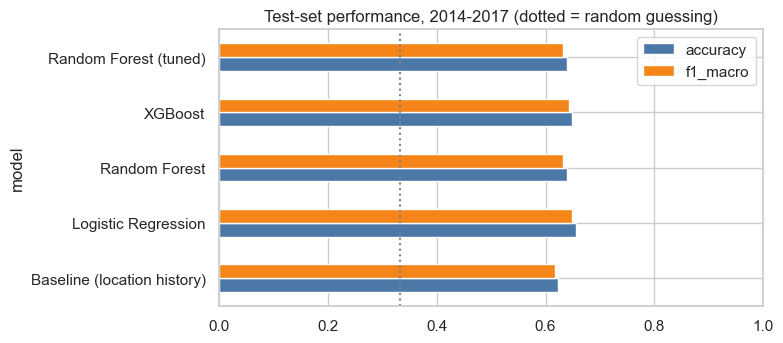

In [6]:
best_name = res[res.model.isin(probas)].sort_values("logloss").model.iloc[0]
print("selected classifier (lowest log-loss on test):", best_name)
fig, ax = plt.subplots(figsize=(8, 3.6))
plot = res.set_index("model")[["accuracy", "f1_macro"]]
plot.plot.barh(ax=ax, color=["#4c78a8", "#f58518"]); ax.axvline(1 / 3, ls=":", c="grey"); ax.set_xlim(0, 1)
ax.set_title("Test-set performance, 2014-2017 (dotted = random guessing)"); plt.tight_layout()
plt.savefig(FIG / "model_comparison.png", dpi=150); plt.show()

## 5. Evaluate the chosen classifier in depth

              precision    recall  f1-score   support

        Poor      0.800     0.707     0.751       816
     Average      0.569     0.502     0.534       673
        Good      0.572     0.791     0.664       454

    accuracy                          0.656      1943
   macro avg      0.647     0.667     0.649      1943
weighted avg      0.667     0.656     0.655      1943



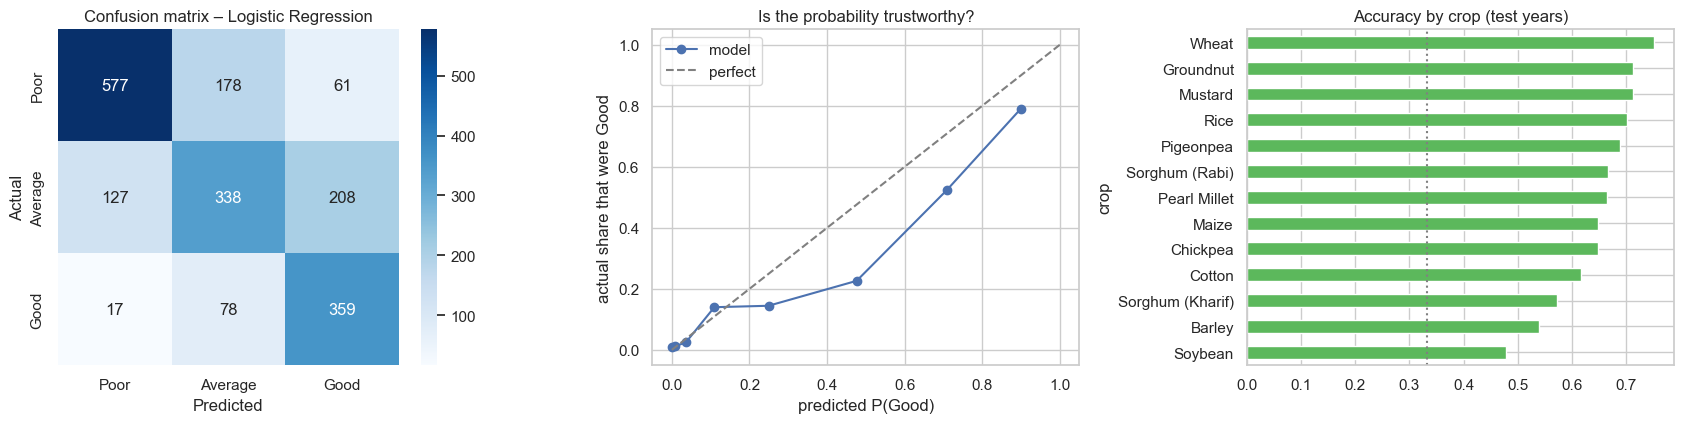

In [7]:
final = {"Random Forest (tuned)": rf}.get(best_name) or models[best_name]
P = probas[best_name]; pred = P.argmax(1)
print(classification_report(yte, pred, target_names=outlook.CLASSES, digits=3))

cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=outlook.CLASSES, yticklabels=outlook.CLASSES, ax=ax[0])
ax[0].set_title(f"Confusion matrix – {best_name}"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")

# how good is "P(Good)" as a likelihood?  (calibration)
frac, mp = calibration_curve(yte == 2, P[:, 2], n_bins=8, strategy="quantile")
ax[1].plot(mp, frac, "o-", label="model"); ax[1].plot([0, 1], [0, 1], "--", c="grey", label="perfect")
ax[1].set_xlabel("predicted P(Good)"); ax[1].set_ylabel("actual share that were Good"); ax[1].set_title("Is the probability trustworthy?"); ax[1].legend()

# accuracy by crop
by_crop = pd.DataFrame(dict(crop=data[te].crop.values, ok=(pred == yte))).groupby("crop").ok.mean().sort_values()
by_crop.plot.barh(ax=ax[2], color="#5cb85c"); ax[2].axvline(1 / 3, ls=":", c="grey"); ax[2].set_title("Accuracy by crop (test years)")
plt.tight_layout(); plt.savefig(FIG / "classifier_evaluation.png", dpi=150); plt.show()

### What the model is good at: confident predictions
A farmer cares about *"how much can I trust a 70 % Good?"* Look at accuracy when the model is confident.

In [8]:
conf = P.max(1); rows = []
for lo in [0.0, 0.5, 0.6, 0.7, 0.8]:
    m = conf >= lo
    rows.append(dict(min_confidence=lo, share_of_cases=m.mean(), accuracy=(pred[m] == yte[m]).mean()))
conf_tab = pd.DataFrame(rows)
conf_tab.round(3)

,min_confidence,share_of_cases,accuracy
0,0.0,1.000,0.656
1,0.5,0.890,0.678
2,0.6,0.660,0.735
3,0.7,0.460,0.792
4,0.8,0.289,0.849


## 6. What drives the prediction? (permutation importance on the test years)
Shuffle one feature at a time and see how much accuracy drops. Features are grouped for readability.

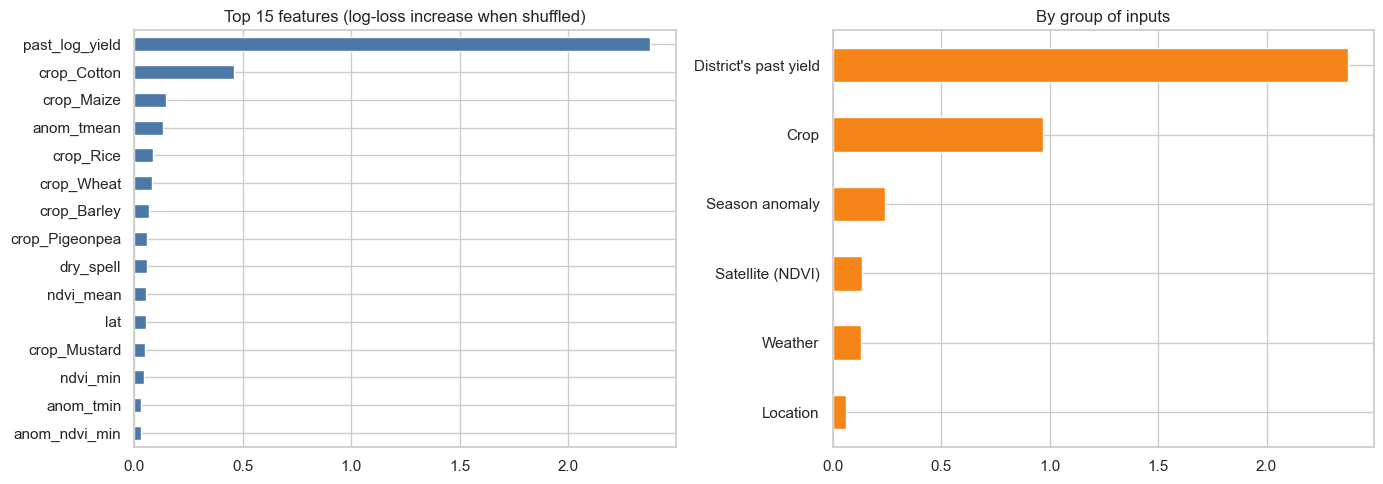

In [9]:
imp = permutation_importance(final, Xte_f, yte, n_repeats=5, random_state=SEED, scoring="neg_log_loss", n_jobs=1)
imp = pd.Series(imp.importances_mean, index=feature_names).sort_values(ascending=False)
def group(n):
    if n == "past_log_yield": return "District's past yield"
    if n.startswith("crop_"): return "Crop"
    if n.startswith("state_") or n in ("lat", "lon"): return "Location"
    if n.startswith("anom_"): return "Season anomaly"
    if "ndvi" in n or "evi" in n: return "Satellite (NDVI)"
    return "Weather"
grp = imp.groupby(imp.index.map(group)).sum().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp.head(15)[::-1].plot.barh(ax=ax[0], color="#4c78a8"); ax[0].set_title("Top 15 features (log-loss increase when shuffled)")
grp.plot.barh(ax=ax[1], color="#f58518"); ax[1].set_title("By group of inputs")
plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(6.2, 3.6)); grp.plot.barh(ax=ax, color="#2f6b3a")
ax.set_title("Importance by group of inputs"); ax.set_xlabel("increase in log-loss when shuffled")
plt.tight_layout(); plt.savefig(FIG / "feature_importance_groups.png", dpi=170); plt.close()

## 7. Secondary head: expected yield (kg/ha) with MAE / RMSE / R²
A Random Forest *regressor* predicts the trend-adjusted log-yield. We convert back to kg/ha. It also gives us a spread
(`sigma`) used for the 80 % range and for the disease-adjusted outlook in notebook 04.

              Random Forest  Baseline: district's past average
MAE (kg/ha)         421.749                            414.274
RMSE (kg/ha)        742.157                            792.426
R²                    0.698                              0.655

residual std in log space (sigma) = 0.522


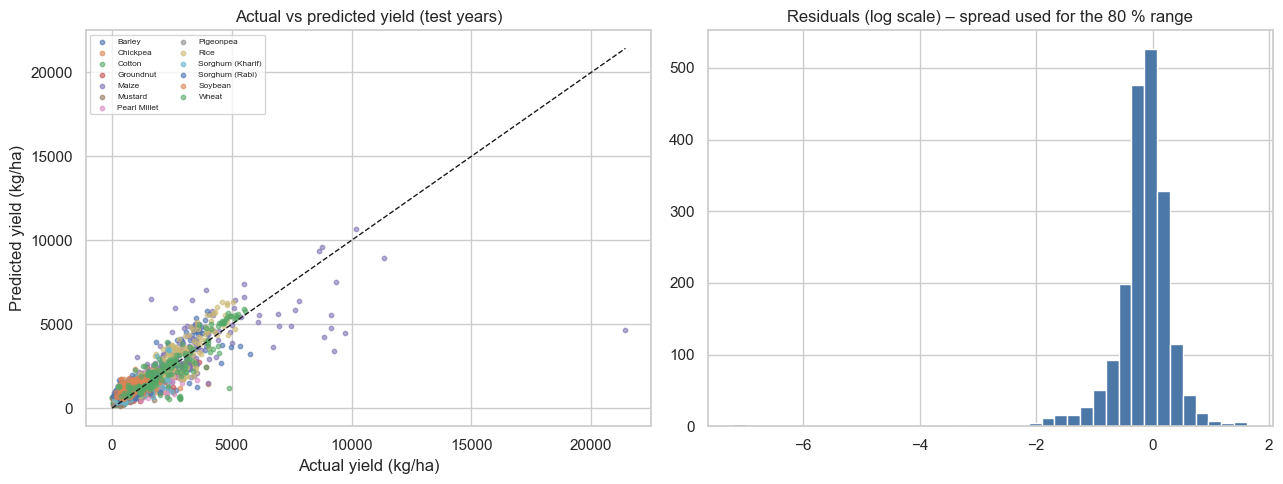

In [10]:
ylog = np.log(data.adj_yield.values)
reg = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, max_features=0.4, n_jobs=-1, random_state=SEED).fit(Xtr_f, ylog[tr])
pr = reg.predict(Xte_f)
pred_kg = np.exp(pr) * data[te].trend_factor.values; act_kg = data[te].yield_kg_ha.values
base_kg = data[te].join(data[tr].groupby(["crop", "district"]).yield_kg_ha.mean().rename("b"), on=["crop", "district"]).b.fillna(data[tr].yield_kg_ha.mean()).values
tab = pd.DataFrame({"Random Forest": [mean_absolute_error(act_kg, pred_kg), mean_squared_error(act_kg, pred_kg) ** .5, r2_score(act_kg, pred_kg)],
                    "Baseline: district's past average": [mean_absolute_error(act_kg, base_kg), mean_squared_error(act_kg, base_kg) ** .5, r2_score(act_kg, base_kg)]},
                   index=["MAE (kg/ha)", "RMSE (kg/ha)", "R²"]).round(3)
print(tab)
resid = ylog[te] - pr; sigma = float(resid.std())
print(f"\nresidual std in log space (sigma) = {sigma:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c, g in data[te].assign(pred=pred_kg).groupby("crop"): ax[0].scatter(g.yield_kg_ha, g.pred, s=10, alpha=.6, label=c)
mx = max(act_kg.max(), pred_kg.max()); ax[0].plot([0, mx], [0, mx], "k--", lw=1)
ax[0].set_xlabel("Actual yield (kg/ha)"); ax[0].set_ylabel("Predicted yield (kg/ha)"); ax[0].set_title("Actual vs predicted yield (test years)"); ax[0].legend(fontsize=6, ncol=2)
ax[1].hist(resid, bins=40, color="#4c78a8"); ax[1].set_title("Residuals (log scale) – spread used for the 80 % range")
plt.tight_layout(); plt.savefig(FIG / "yield_actual_vs_predicted.png", dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.scatter(act_kg, pred_kg, s=9, alpha=.5, color="#2f6b3a"); ax.plot([0, mx], [0, mx], "k--", lw=1)
ax.set_xlabel("Actual yield (kg/ha)"); ax.set_ylabel("Predicted yield (kg/ha)"); ax.set_title("Actual vs predicted yield, test years")
plt.tight_layout(); plt.savefig(FIG / "yield_scatter.png", dpi=170); plt.close()

## 8. Re-train on all years and save the predictor
The test years are now allowed into training for the final model that a user will query. (All evaluation numbers above came
from the earlier, train-only fit.)

In [11]:
# final model: history from all years (leave-one-year-out for the rows it trains on)
all_rows = np.ones(len(data), dtype=bool)
data_all = data.assign(past_log_yield=past_yield(data, all_rows))
Xall = outlook.build_X(data_all, normals, fcols, crops, states).fillna(0)
hist = data.groupby(["crop", "district"]).log_adj.mean().rename("past_log_yield").reset_index()
final_all = (RandomForestClassifier(n_estimators=600, n_jobs=-1, random_state=SEED, **grid.best_params_) if best_name == "Random Forest (tuned)"
             else __import__("sklearn.base", fromlist=["clone"]).clone(final)).fit(Xall, y)
reg_all = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, max_features=0.4, n_jobs=-1, random_state=SEED).fit(Xall, ylog)
bundle = dict(clf=final_all, reg=reg_all, feature_names=feature_names, fcols=fcols, crops=crops, states=states,
              normals=normals, feat=feat, coords=coords, meta=meta, sigma=sigma, ref_year=2017,
              hist=hist, crop_mean_log=data.groupby("crop").log_adj.mean().to_dict(),
              crop_season=data.drop_duplicates("crop").set_index("crop").season.to_dict())
joblib.dump(bundle, MODELS / "yield_outlook.joblib", compress=3)
res.to_csv(PROC / "model_results.csv", index=False)
json.dump(dict(best=best_name, regression=tab.to_dict(), sigma=sigma, confusion=cm.tolist(),
               n_rows=int(len(data)), n_train=int(tr.sum()), n_test=int(te.sum()), n_districts=int(data.district.nunique()),
               n_states=int(data.state.nunique()), n_crops=int(data.crop.nunique()), n_features=int(X.shape[1]),
               baseline_accuracy=float(accuracy_score(yte, base_pred)), baseline_f1=float(f1_score(yte, base_pred, average="macro")),
               confidence=conf_tab.to_dict(orient="records"), importance_groups=grp.to_dict(),
               top_features=imp.head(8).to_dict(), accuracy_by_crop=by_crop.to_dict(),
               per_class=classification_report(yte, pred, target_names=outlook.CLASSES, output_dict=True)),
          open(PROC / "model_summary.json", "w"), indent=1)
print("saved", MODELS / "yield_outlook.joblib")

saved C:\Users\SHIVANI\OneDrive\Desktop\predictive\models\yield_outlook.joblib


## 9. The product: **crop + location + season → likelihood**
`YieldOutlook.predict(...)` takes exactly the three user inputs (plus an optional scenario or past year).

In [12]:
print(inspect.getsource(outlook.YieldOutlook.predict))

    def predict(self, crop, state, district, season, year=None, scenario="normal", yield_loss=0.0):
        """Main entry point.  yield_loss (0-1) is an optional disease-loss fraction (notebook 04)."""
        if crop not in self.crop_season:
            raise ValueError(f"Unknown crop {crop!r}. Choose from {self.crops}")
        if self.crop_season[crop] != season:
            raise ValueError(f"{crop} is a {self.crop_season[crop]} crop here, not a {season} crop.")
        loc = self.coords[(self.coords.state == state) & (self.coords.district == district)]
        if loc.empty:
            raise ValueError(f"Unknown location {district}, {state}.")
        cond, desc = self._conditions(state, district, season, year, scenario)
        h = self.hist[(self.hist.crop == crop) & (self.hist.district == district)]
        past = float(h.past_log_yield.iloc[0]) if len(h) else float(self.crop_mean_log[crop])
        row = pd.DataFrame([dict(crop=crop, state=state, district=district, season=seas

In [13]:
yo = outlook.YieldOutlook()

def pick(crop, k=0):
    """A (state, district) with plenty of history for this crop, so the demo works for any district set."""
    g = data[data.crop == crop].groupby(["state", "district"]).size().sort_values(ascending=False)
    return g.index[k]

for crop, season in [("Wheat", "Rabi"), ("Maize", "Kharif"), ("Rice", "Kharif")]:
    st, di = pick(crop)
    print(yo.report(crop=crop, state=st, district=di, season=season)); print()

Wheat · Kurnool, Andhra Pradesh · Rabi   [typical season (district average)]
  P(Good) = 0%   P(Average) = 7%   P(Poor) = 93%   →  most likely: Poor
  Expected yield ≈ 856 kg/ha  (80% range 439-1,671); 'Good' means above ≈ 2,837 kg/ha

Maize · Ananthapur, Andhra Pradesh · Kharif   [typical season (district average)]
  P(Good) = 91%   P(Average) = 9%   P(Poor) = 0%   →  most likely: Good
  Expected yield ≈ 5,820 kg/ha  (80% range 2,982-11,358); 'Good' means above ≈ 3,832 kg/ha



Rice · Ananthapur, Andhra Pradesh · Kharif   [typical season (district average)]
  P(Good) = 75%   P(Average) = 24%   P(Poor) = 2%   →  most likely: Good
  Expected yield ≈ 3,831 kg/ha  (80% range 1,963-7,477); 'Good' means above ≈ 3,458 kg/ha



### Same crop, same place: what does a dry vs wet season do?

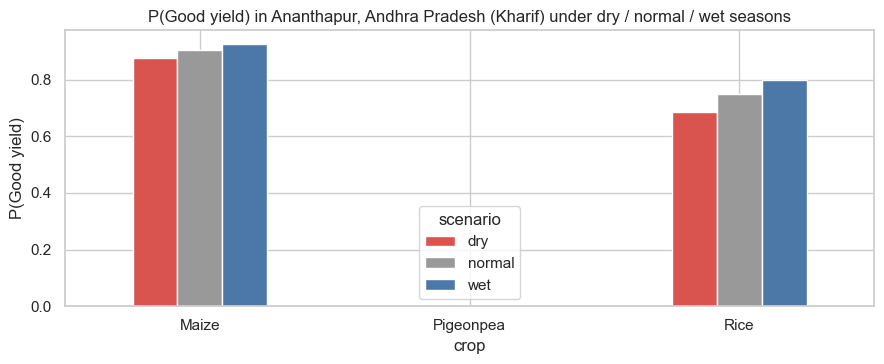

,crop,scenario,Poor,Average,Good,expected_kg_ha
0,Maize,dry,0.01,0.11,0.88,5419.74
1,Maize,normal,0.00,0.09,0.91,5819.81
2,Maize,wet,0.00,0.07,0.93,6278.39
3,Rice,dry,0.03,0.28,0.68,3945.12
4,Rice,normal,0.02,0.24,0.75,3831.05
5,Rice,wet,0.01,0.19,0.80,3891.23
6,Pigeonpea,dry,0.99,0.01,0.00,260.56
7,Pigeonpea,normal,0.99,0.01,0.00,303.21
8,Pigeonpea,wet,0.98,0.02,0.00,386.61


In [14]:
loc_state, loc_dist = pick("Maize")
rows = []
for crop in ["Maize", "Rice", "Pigeonpea"]:
    for sc in ["dry", "normal", "wet"]:
        try:
            r = yo.predict(crop=crop, state=loc_state, district=loc_dist, season="Kharif", scenario=sc)
            rows.append(dict(crop=crop, scenario=sc, Poor=r["p_poor"], Average=r["p_average"], Good=r["p_good"], expected_kg_ha=r["expected_yield"]))
        except ValueError as e: print("skip", crop, e)
sc = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.8))
piv = sc.pivot(index="crop", columns="scenario", values="Good")[["dry", "normal", "wet"]]
piv.plot.bar(ax=ax, color=["#d9534f", "#999999", "#4c78a8"]); ax.set_ylabel("P(Good yield)"); ax.set_title(f"P(Good yield) in {loc_dist}, {loc_state} (Kharif) under dry / normal / wet seasons")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG / "scenario_example.png", dpi=150); plt.show()
sc.round(2)

### Replay a real past season and compare with what happened
Pick a year (here a test year the model never trained on in section 3) and compare the model's verdict with the true label.

In [15]:
chk = data[(data.year == 2015)].sample(6, random_state=4)
for _, r in chk.iterrows():
    o = yo.predict(crop=r.crop, state=r.state, district=r.district, season=r.season, year=int(r.year))
    print(f"{r.crop:14s}{r.district[:14]:15s}{int(r.year)}  predicted {o['verdict']:8s} (Good {o['p_good']:.0%})   actual: {r.label_name:8s} ({r.yield_kg_ha:,.0f} kg/ha)")
print("\n(note: the saved predictor was trained on all years, so this replay is a demo, not an evaluation)")

Mustard       Surguja        2015  predicted Poor     (Good 0%)   actual: Poor     (591 kg/ha)
Soybean       Medak          2015  predicted Poor     (Good 12%)   actual: Poor     (954 kg/ha)
Maize         Raigarh        2015  predicted Poor     (Good 2%)   actual: Poor     (1,683 kg/ha)


Maize         Beed           2015  predicted Poor     (Good 0%)   actual: Poor     (314 kg/ha)
Wheat         Shahabad (now  2015  predicted Average  (Good 26%)   actual: Average  (2,401 kg/ha)
Rice          Medak          2015  predicted Good     (Good 54%)   actual: Average  (2,849 kg/ha)

(note: the saved predictor was trained on all years, so this replay is a demo, not an evaluation)


## Takeaways
* The model turns *crop + place + season* into a calibrated-ish probability of Good / Average / Poor, with a yield estimate and reasons.
* It beats the location-history baseline by a few points of accuracy and clearly in AUC (section 3 table), but most of the skill
  comes from knowing the district's own history (section 6). Weather and NDVI add a modest, real improvement on top.
* The regressor's R² and RMSE beat the district's past average, while its MAE is about the same: do not oversell the yield number.
* Predicting an entire season in advance, with only normals and a rainfall scenario, is inherently less precise than a mid-season
  update with real NDVI. The confident cases (section 5) are where to trust it most.
* **Limitations:** 75 districts, district-level (not field-level) yields, one NDVI pixel box per district, labels are relative to the
  crop's national spread. Details in the README / slides.